---
title: "3.1.d Escenarios: crecientes en un clima cambiante"
short_title: "d. Escenarios"
subtitle: "Proyecciones de lluvia del ensamble CMIP6, intensificación del ciclo hidrológico y alerta temprana"
description: "Escenarios de cambio climático para las crecientes del Amazonas en Leticia y pronóstico estacional de GloFAS."
keywords: [inundación, CMIP6, CCKP, escenarios, alerta temprana, GloFAS]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/31_inundacion/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El Amazonas en Leticia integra la lluvia de una cuenca de más de 700 000 km² que incluye los Andes de Perú y
Ecuador. Por eso, el cambio en las crecientes no depende de la lluvia sobre la ciudad, sino del ciclo
hidrológico de toda la cuenca alta. Esta página combina tres miradas: lo que **ya está pasando** (registros
largos), lo que **proyectan los modelos** CMIP6 para la lluvia extrema y lo que **se puede anticipar** con el
pronóstico de GloFAS.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, hidro, viz
from leticia.config import aoi_cfg

## 1. Lo observado: más amplitud entre crecientes y vaciantes

El registro de Manaos (1903–presente) muestra que la amplitud anual entre crecientes y vaciantes extremas
creció unos 150 cm en los últimos 30 años, y que las grandes crecientes pasaron de una cada ~20 años a una
cada ~4 años desde 2000 [@marengo2021spa22; @marengo2024spa]. La serie de Leticia es más corta, pero permite
mirar la misma señal: la diferencia entre el máximo y el mínimo de cada año.

Años completos: 25. Pendiente de Sen: 0.52 m por década (p = 0.15).

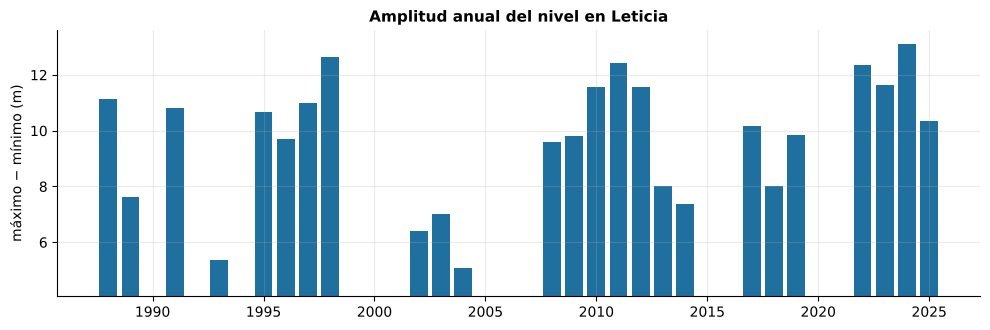

In [3]:
nivel = hidro.limpiar_nivel(fuentes.nivel_rio())
mx, mn = hidro.extremos_anuales(nivel, "max"), hidro.extremos_anuales(nivel, "min")
amp = (mx["valor"] - mn["valor"]).dropna() / 100
mk = hidro.mann_kendall(amp)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(amp.index, amp, color=viz.AZUL_RIO)
ax.set_ylabel("máximo − mínimo (m)")
ax.set_title("Amplitud anual del nivel en Leticia")
ax.set_ylim(amp.min() - 1, amp.max() + 0.5)
fig.tight_layout()
display(Markdown(f"Años completos: {mk['n']}. Pendiente de Sen: **{mk['sen']*10:.2f} m por década** (p = {mk['p']:.2f})."))

## 2. Lo proyectado: lluvia media y extrema (CMIP6, Banco Mundial)

In [4]:
VARS = {"pr": "lluvia anual (mm)", "rx1day": "lluvia máxima en 1 día (mm)", "rx5day": "lluvia máxima en 5 días (mm)"}
tabla = fuentes.cckp_tabla(list(VARS))
base = fuentes.cckp_historico(list(VARS))
piv = tabla.pivot_table(index=["variable", "escenario"], columns=["periodo", "percentil"], values="valor")
piv.index = piv.index.set_levels([[VARS[v] for v in piv.index.levels[0]], [viz.NOMBRE_ESC[e] for e in piv.index.levels[1]]])
display(Markdown("**Cambio respecto a 1995–2014** (mediana del ensamble y rango p10–p90 de 25 modelos):"))
display(piv.round(1))
display(base.rename(index=VARS).round(1).to_frame("climatología 1995–2014"))

Cambio respecto a 1995–2014 (mediana del ensamble y rango p10–p90 de 25 modelos):

periodo                                2040-2059                2080-2099               
percentil                                 median     p10    p90    median     p10    p90
variable                     escenario                                                  
lluvia anual (mm)            SSP1-2.6     -70.30 -179.50 140.50    -40.80 -238.40 137.20
                             SSP2-4.5     -70.00 -253.10  87.80   -103.10 -417.60 205.70
                             SSP5-8.5    -105.30 -370.10 213.20   -259.00 -641.10 285.90
lluvia máxima en 1 día (mm)  SSP1-2.6       2.20   -2.40   8.90      2.90   -2.50   5.80
                             SSP2-4.5       2.80   -2.20   9.80      3.60   -1.00  10.60
                             SSP5-8.5       3.70   -2.80   8.00      7.90   -1.00  24.30
lluvia máxima en 5 días (mm) SSP1-2.6       4.60   -4.20  14.00      4.90   -0.40  11.80
                             SSP2-4.5       5.30   -5.10  12.00      9.10    1.50  19.10
                             SSP5-8.5       4.80   -0.70  20.60      9.90   -2.90  30.80

,climatología 1995–2014
lluvia anual (mm),"2,906.60"
lluvia máxima en 1 día (mm),37.40
lluvia máxima en 5 días (mm),101.70


In [5]:
viz.pie(viz.nota_fuente("proyecciones_cckp") + " Reducción de escala NEX-GDDP-CMIP6 (Thrasher et al., 2022).")

Fuente: Banco Mundial – Climate Change Knowledge Portal (CCKP) — CMIP6 0,25° (reducción de escala estadística), SSP1-2.6, SSP2-4.5, SSP5-8.5. Reducción de escala NEX-GDDP-CMIP6 (Thrasher et al., 2022).

**Lectura.** Para la celda de Leticia el ensamble proyecta **poco cambio en la lluvia anual** pero **aumentos en
la lluvia extrema de 1 y 5 días**, mayores con más emisiones. Para las crecientes del Amazonas importa además
lo que ocurra en los Andes y la cuenca alta; los estudios regionales proyectan más lluvia en el occidente y
noroccidente amazónico en la temporada húmeda y una estación seca más larga en el sur
[@marengo2021spa22; @castellanos2022ipcc]. La señal coincide con lo observado: **extremos en ambos sentidos**.

## 3. Escenarios de sensibilidad para Leticia

In [6]:
from leticia import espacial, exposicion
from leticia.config import parametros
edif = exposicion.edificaciones_urbanas()
pts = edif.representative_point().to_crs(4326)
dem = fuentes.raster_estatico("cop-dem-glo-30", "data")
occ = fuentes.raster_estatico("jrc-gsw", "occurrence")
hand = espacial.altura_sobre_agua(dem, occ >= 90)
h_edif = np.nan_to_num(hand.interp(x=("p", pts.x.values), y=("p", pts.y.values), method="nearest").values, nan=99)
# Calibración: altura sobre el río que deja por debajo tantas edificaciones como expone el mapa de 100 años del JRC
d100 = fuentes.inundacion_jrc(100)
prof = np.nan_to_num(d100.interp(x=("p", pts.x.values), y=("p", pts.y.values), method="nearest").values)
n_jrc = int((prof >= parametros()["inundacion"]["profundidad_minima_m"]).sum())
alturas = np.sort(h_edif)
h_ref = float(alturas[min(n_jrc, len(alturas) - 1)])
ret = hidro.niveles_retorno_ic(mx["valor"].values, [100])
filas = []
for nombre, delta in (("Creciente de 100 años actual", 0.0), ("+0,5 m (intensificación moderada)", 0.5),
                      ("+1,0 m (intensificación alta)", 1.0), ("+2,0 m (extremo)", 2.0)):
    bajo = h_edif <= h_ref + delta
    filas.append({"escenario": nombre, "nivel en la regla (m)": ret.loc[100, "nivel"] / 100 + delta,
                  "edificaciones": int(bajo.sum()), "personas": edif.loc[bajo, "poblacion"].sum()})
tabla = pd.DataFrame(filas).set_index("escenario")
tabla["aumento de personas (%)"] = 100 * (tabla["personas"] / tabla["personas"].iloc[0] - 1)
display(tabla.round(1))
display(Markdown(f"Altura de calibración: **{h_ref:.1f} m** sobre el agua permanente (deja por debajo las {n_jrc:,} edificaciones que "
                 "expone el mapa de 100 años del JRC).".replace(",", ".")))

,nivel en la regla (m),edificaciones,personas,aumento de personas (%)
escenario,,,,
Creciente de 100 años actual,18.40,1745,"7,256.90",0.00
"+0,5 m (intensificación moderada)",18.90,2070,"8,850.10",22.00
"+1,0 m (intensificación alta)",19.40,2464,"11,304.70",55.80
"+2,0 m (extremo)",20.40,3586,"18,359.20",153.00


Altura de calibración: 11.6 m sobre el agua permanente (deja por debajo las 1.744 edificaciones que expone el mapa de 100 años del JRC).

Los escenarios suman 0,5, 1 y 2 m a la creciente de 100 años; el aumento de amplitud observado en Manaos en
30 años es del orden de 1,5 m [@marengo2024spa]. Para traducirlos en exposición se usa la altura de cada
edificación sobre el río, calibrada para que el escenario actual reproduzca el conteo del mapa del JRC. El
resultado es una **sensibilidad**: cuánto crece la exposición por cada medio metro de creciente adicional. No
reemplaza un modelo hidráulico local, que es la primera recomendación de este flujo.

## 4. Anticipar: pronóstico de caudal de GloFAS

Nivel equivalente en la regla de Leticia al final del pronóstico (2027-01-27): ≈ 14.9 m (relación nivel–caudal, R² = 0.82).

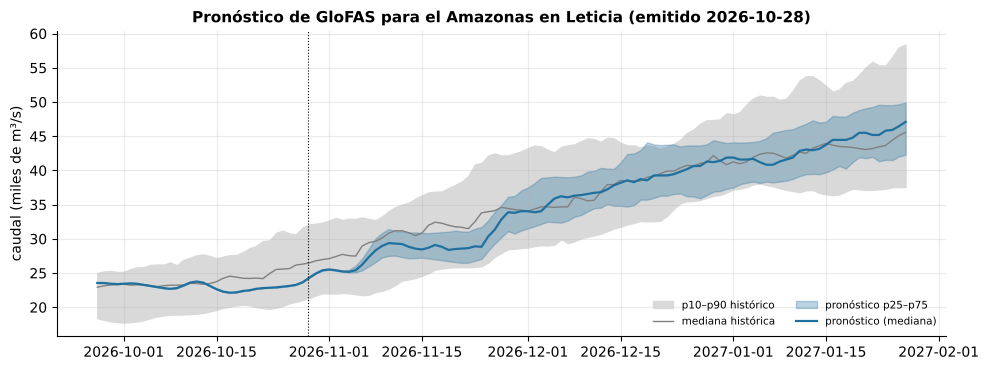

In [7]:
pron = intentar(fuentes.pronostico_glofas, mensaje="El pronóstico de GloFAS no respondió")
if pron is not None:
    q = fuentes.caudal_glofas()
    coef, r2, _ = hidro.relacion_nivel_caudal(nivel, q)
    clim = q.groupby(q.index.dayofyear).quantile([0.1, 0.5, 0.9]).unstack()
    fig, ax = plt.subplots(figsize=(10, 3.8))
    d = np.minimum(np.asarray(pron.index.dayofyear), 365)
    ax.fill_between(pron.index, clim.loc[d, 0.1].values / 1000, clim.loc[d, 0.9].values / 1000, color="0.85", label="p10–p90 histórico")
    ax.plot(pron.index, clim.loc[d, 0.5].values / 1000, color="0.5", lw=1, label="mediana histórica")
    ax.fill_between(pron.index, pron["river_discharge_p25"] / 1000, pron["river_discharge_p75"] / 1000, color=viz.AZUL_RIO, alpha=0.3,
                    label="pronóstico p25–p75")
    ax.plot(pron.index, pron["river_discharge_median"] / 1000, color=viz.AZUL_RIO, lw=1.6, label="pronóstico (mediana)")
    ax.axvline(pd.Timestamp.today(), color="k", lw=0.8, ls=":")
    ax.set_ylabel("caudal (miles de m³/s)")
    ax.set_title(f"Pronóstico de GloFAS para el Amazonas en Leticia (emitido {pd.Timestamp.today():%Y-%m-%d})")
    ax.legend(ncol=2, fontsize=7.5)
    fig.tight_layout()
    fin = pron["river_discharge_median"].dropna()
    display(Markdown(f"Nivel equivalente en la regla de Leticia al final del pronóstico ({fin.index[-1]:%Y-%m-%d}): "
                     f"**≈ {np.polyval(coef, fin.iloc[-1]) / 100:.1f} m** (relación nivel–caudal, R² = {r2:.2f})."))

:::{tip} Uso para la gestión del riesgo
La creciente del Amazonas se anuncia con semanas de anticipación. Un protocolo local que vincule los
pronósticos de GloFAS y los boletines del IDEAM con umbrales en la regla de Leticia —acordados con la Alcaldía,
la Capitanía de Puerto y las comunidades ribereñas— permite activar evacuaciones preventivas y proteger
bienes antes de que el agua llegue. La validación de [3.1.b](b_amenaza.ipynb) muestra que GloFAS adelanta el pico
unas cuatro semanas y ordena mal la magnitud de cada creciente: el nivel equivalente de arriba indica la tendencia,
y la decisión debe apoyarse en la regla de Leticia y en los boletines del IDEAM.
:::